# Khám phá dữ liệu và trực quan hóa MNIST

**Nhận dạng chữ số viết tay · Nhóm 03**

## 1. Thư viện và thiết lập

In [1]:
import importlib.util
import subprocess
import sys

packages = {
    'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
    'seaborn': 'seaborn', 'sklearn': 'scikit-learn>=1.5',
    'cv2': 'opencv-python-headless', 'skimage': 'scikit-image',
    'scipy': 'scipy', 'joblib': 'joblib', 'threadpoolctl': 'threadpoolctl',
}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Python:', sys.version.split()[0])
print('Các thư viện đã sẵn sàng.')

Python: 3.12.14
Các thư viện đã sẵn sàng.


In [2]:
from pathlib import Path
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import sklearn
from IPython.display import display, HTML, Markdown
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from skimage.feature import hog
from threadpoolctl import threadpool_limits

SEED = 42
CPU_THREADS = min(4, os.cpu_count() or 2)
THREAD_LIMITER = threadpool_limits(limits=CPU_THREADS)
rng = np.random.RandomState(SEED)
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 115, 'savefig.dpi': 160, 'axes.titlesize': 12,
                     'axes.labelsize': 10, 'font.size': 10})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 100)
print(f'NumPy {np.__version__} | scikit-learn {sklearn.__version__} | CPU threads: {CPU_THREADS}')

OUTPUT_DIR = Path.cwd() / 'mnist_eda_output'
FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def show_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close()

NumPy 2.5.4 | scikit-learn 1.8.0 | CPU threads: 4


## 2. Nạp dữ liệu

In [3]:
import urllib.request

DATA_PATH = None  # Có thể điền đường dẫn tới mnist.npz đang có.

def load_mnist(path=None):
    candidates = []
    if path is not None:
        candidates.append(Path(path))
    for folder in [Path.cwd(), Path.cwd().parent, Path('/kaggle/working'), Path('/content')]:
        candidates.extend([folder / 'mnist.npz', folder / 'data/mnist.npz'])
    if Path('/kaggle/input').exists():
        candidates.extend(sorted(Path('/kaggle/input').rglob('mnist.npz')))
    found = next((p for p in candidates if p.is_file()), None)
    if found is None:
        found = Path.cwd() / 'mnist.npz'
        url = 'https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz'
        print('Đang tải MNIST từ kho TensorFlow/Keras...')
        try:
            urllib.request.urlretrieve(url, found)
        except Exception as exc:
            raise RuntimeError('Không tải được MNIST. Đặt mnist.npz cạnh notebook hoặc gán DATA_PATH tới tệp dữ liệu.') from exc
    with np.load(found, allow_pickle=False) as data:
        arrays = [data[k] for k in ['x_train', 'y_train', 'x_test', 'y_test']]
    x_train, y_train, x_test, y_test = arrays
    assert x_train.shape == (60000, 28, 28) and x_test.shape == (10000, 28, 28)
    assert y_train.shape == (60000,) and y_test.shape == (10000,)
    print('Dữ liệu:', found.name)
    return x_train, y_train, x_test, y_test

x_train_raw, y_train_full, x_test_raw, y_test = load_mnist(DATA_PATH)
display(pd.DataFrame([
    {'Tập': 'Train gốc', 'Số ảnh': len(y_train_full), 'Kích thước': '28 × 28', 'Kiểu pixel': str(x_train_raw.dtype), 'Số lớp': len(np.unique(y_train_full))},
    {'Tập': 'Test', 'Số ảnh': len(y_test), 'Kích thước': '28 × 28', 'Kiểu pixel': str(x_test_raw.dtype), 'Số lớp': len(np.unique(y_test))},
]))

Dữ liệu: mnist.npz


,Tập,Số ảnh,Kích thước,Kiểu pixel,Số lớp
0,Train gốc,60000,28 × 28,uint8,10
1,Test,10000,28 × 28,uint8,10


## 3. Kiểm tra chất lượng dữ liệu

Ảnh và nhãn được kiểm tra kích thước, miền giá trị, dữ liệu thiếu và ảnh trống.
Các mẫu vẫn được giữ nguyên khi phân tích; notebook không tự sửa nhãn.

In [4]:
quality_rows = []
for name, images, labels in [('Train', x_train_raw, y_train_full), ('Test', x_test_raw, y_test)]:
    quality_rows.append({'Tập': name, 'NaN pixel': int(np.isnan(images).sum()),
                         'NaN nhãn': int(np.isnan(labels).sum()), 'Pixel nhỏ nhất': int(images.min()),
                         'Pixel lớn nhất': int(images.max()), 'Ảnh trống': int((images.sum(axis=(1, 2)) == 0).sum()),
                         'Nhãn ngoài 0–9': int(((labels < 0) | (labels > 9)).sum())})
quality = pd.DataFrame(quality_rows)
display(quality)
assert quality[['NaN pixel', 'NaN nhãn', 'Nhãn ngoài 0–9']].to_numpy().sum() == 0

,Tập,NaN pixel,NaN nhãn,Pixel nhỏ nhất,Pixel lớn nhất,Ảnh trống,Nhãn ngoài 0–9
0,Train,0,0,0,255,0,0
1,Test,0,0,0,255,0,0


## 4. Quan sát các kiểu viết từ 0 đến 9

Mỗi hàng là một lớp chữ số. Sáu ảnh trong hàng được lấy từ tập train với seed cố định.

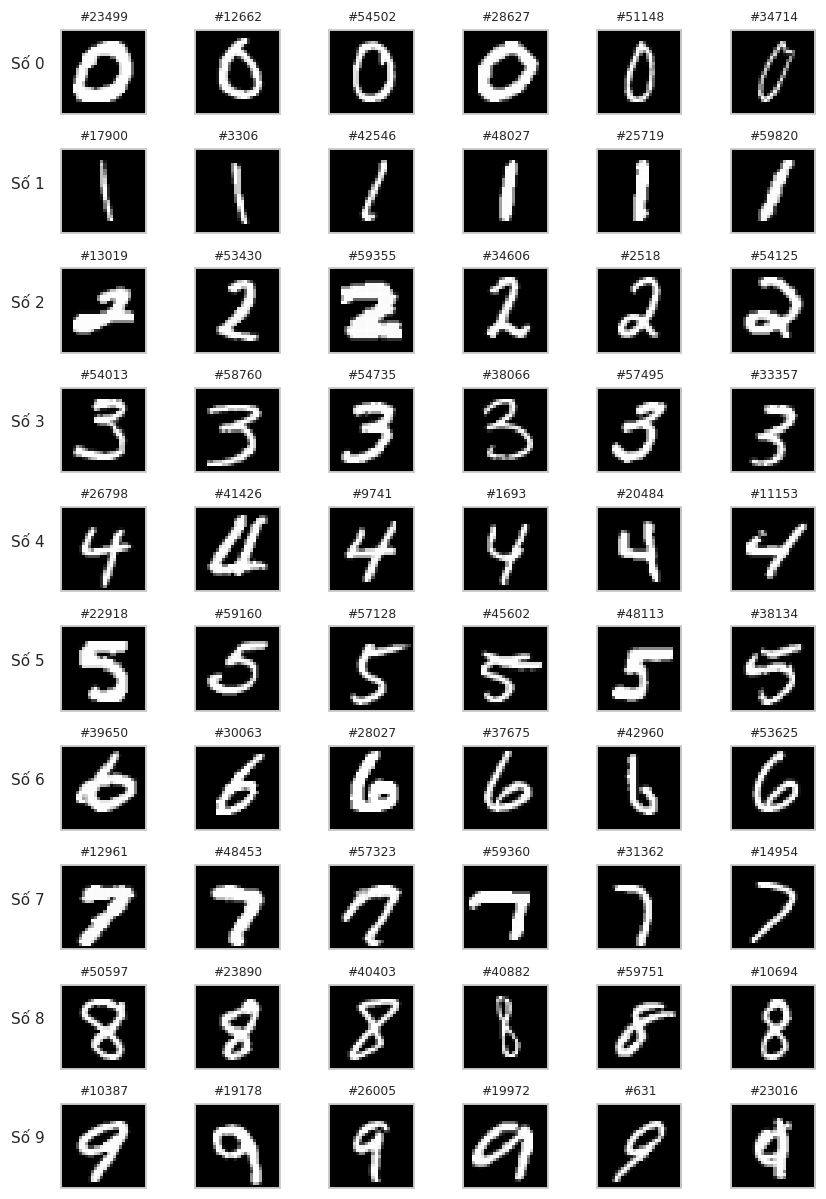

In [5]:
fig, axes = plt.subplots(10, 6, figsize=(8, 11))
for digit in range(10):
    indices = rng.choice(np.flatnonzero(y_train_full == digit), 6, replace=False)
    for column, index in enumerate(indices):
        ax = axes[digit, column]
        ax.imshow(x_train_raw[index], cmap='gray', vmin=0, vmax=255)
        ax.set_title(f'#{index}', fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
        if column == 0:
            ax.set_ylabel(f'Số {digit}', rotation=0, labelpad=22, fontsize=10)
show_figure('01_anh_mau_tung_lop')

## 5. Phân bố lớp và mức cân bằng

Bảng ghi số lượng thực tế của từng lớp ở hai tập. Entropy được so với mức tối đa log₂(10).

,Chữ số,Train,Test,Train (%),Test (%)
0,0,5923,980,9.87,9.80
1,1,6742,1135,11.24,11.35
2,2,5958,1032,9.93,10.32
3,3,6131,1010,10.22,10.10
4,4,5842,982,9.74,9.82
5,5,5421,892,9.04,8.92
6,6,5918,958,9.86,9.58
7,7,6265,1028,10.44,10.28
8,8,5851,974,9.75,9.74
9,9,5949,1009,9.92,10.09


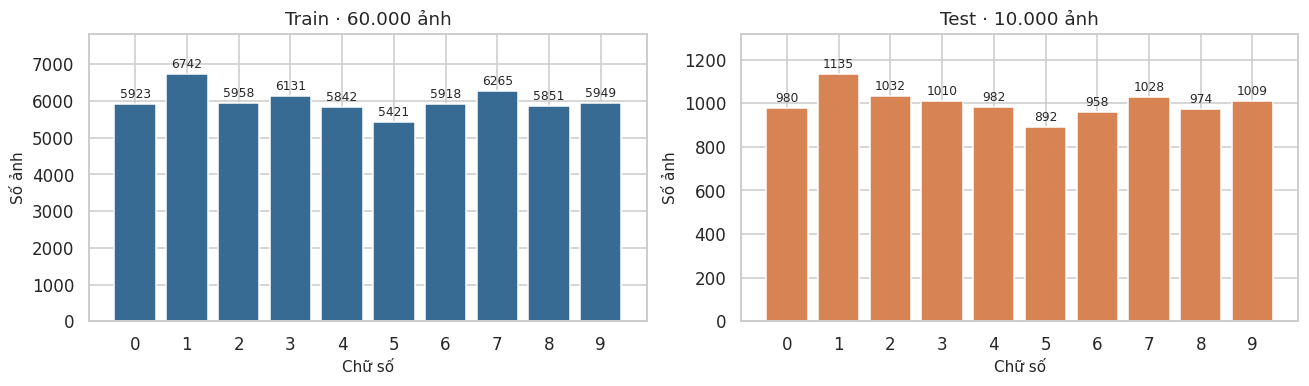

,Tập,Entropy (bit),Tỷ lệ so với cực đại (%),Tỷ số lớp nhiều / ít
0,Train,3.3199,99.9381,1.2437
1,Test,3.3194,99.9246,1.2724


In [6]:
train_counts = np.bincount(y_train_full, minlength=10)
test_counts = np.bincount(y_test, minlength=10)
class_table = pd.DataFrame({'Chữ số': np.arange(10), 'Train': train_counts, 'Test': test_counts,
                            'Train (%)': train_counts / len(y_train_full) * 100,
                            'Test (%)': test_counts / len(y_test) * 100})
display(class_table.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, counts, title, color in zip(axes, [train_counts, test_counts], ['Train · 60.000 ảnh', 'Test · 10.000 ảnh'], ['#376b94', '#d88353']):
    bars = ax.bar(np.arange(10), counts, color=color)
    ax.bar_label(bars, fontsize=8, padding=2)
    ax.set(title=title, xlabel='Chữ số', ylabel='Số ảnh', xticks=np.arange(10))
    ax.set_ylim(0, max(counts) * 1.16)
show_figure('02_phan_bo_lop')

entropy_rows = []
for title, counts in [('Train', train_counts), ('Test', test_counts)]:
    prob = counts / counts.sum()
    entropy = -(prob * np.log2(prob)).sum()
    entropy_rows.append({'Tập': title, 'Entropy (bit)': entropy,
                         'Tỷ lệ so với cực đại (%)': entropy / np.log2(10) * 100,
                         'Tỷ số lớp nhiều / ít': counts.max() / counts.min()})
display(pd.DataFrame(entropy_rows).round(4))

Entropy: Với 10 lớp, cực đại là (log_2 10 = 3,322) bit. Càng gần mức này, các lớp càng cân bằng.

Tỷ lệ so với cực đại: Entropy thực tế chia entropy cực đại

## 6. Phân bố cường độ pixel và chuẩn hóa

Pixel gốc thuộc [0, 255]. Phép chia cho 255 chuyển chúng về [0, 1] mà không thay đổi thứ tự cường độ.

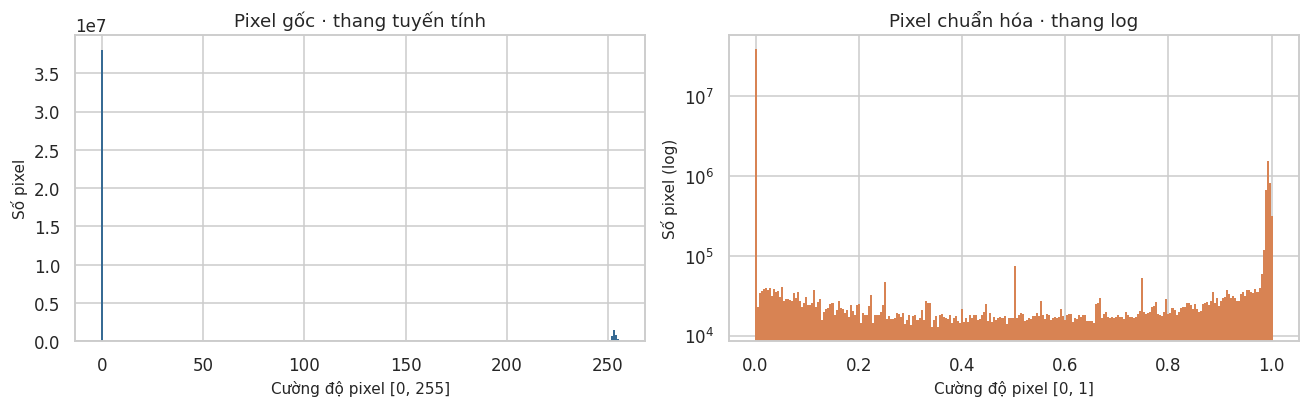

,Đại lượng,Giá trị
0,Pixel nền bằng 0 (%),80.8798
1,Pixel cực đại bằng 255 (%),0.6681
2,Giá trị trung bình sau chuẩn hóa,0.1307


In [7]:
pixel_counts = np.bincount(x_train_raw.reshape(-1), minlength=256)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(np.arange(256), pixel_counts, width=1, color='#376b94', linewidth=0, edgecolor='none')
axes[0].set(title='Pixel gốc · thang tuyến tính', xlabel='Cường độ pixel [0, 255]', ylabel='Số pixel')
axes[1].bar(np.arange(256) / 255, pixel_counts, width=1 / 255, color='#d88353', linewidth=0, edgecolor='none')
axes[1].set_yscale('log')
axes[1].set(title='Pixel chuẩn hóa · thang log', xlabel='Cường độ pixel [0, 1]', ylabel='Số pixel (log)')
show_figure('03_phan_bo_pixel')
display(pd.DataFrame({'Đại lượng': ['Pixel nền bằng 0 (%)', 'Pixel cực đại bằng 255 (%)', 'Giá trị trung bình sau chuẩn hóa'],
                      'Giá trị': [pixel_counts[0] / pixel_counts.sum() * 100,
                                  pixel_counts[-1] / pixel_counts.sum() * 100,
                                  float(np.dot(np.arange(256) / 255, pixel_counts) / pixel_counts.sum())]}).round(4))

## 7. Hình dạng nét và vị trí trọng tâm

Thống kê dùng 5.000 ảnh train. Pixel lớn hơn 0,2 được xem là nét khi đo diện tích;
trọng tâm được tính theo cường độ pixel.

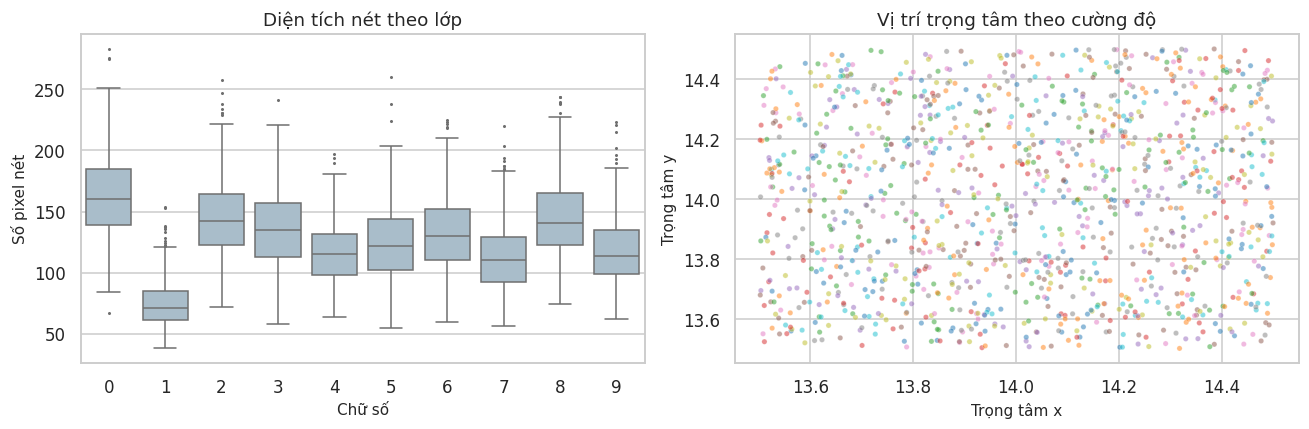

In [8]:
shape_indices = rng.choice(len(y_train_full), 5000, replace=False)
shape_images = x_train_raw[shape_indices].astype(np.float32) / 255
mass = shape_images.sum(axis=(1, 2))
center_x = (shape_images.sum(axis=1) * np.arange(28)).sum(axis=1) / np.maximum(mass, 1e-8)
center_y = (shape_images.sum(axis=2) * np.arange(28)).sum(axis=1) / np.maximum(mass, 1e-8)
shape_table = pd.DataFrame({'Chữ số': y_train_full[shape_indices],
                            'Số pixel nét': (shape_images > 0.2).sum(axis=(1, 2)),
                            'Trọng tâm x': center_x, 'Trọng tâm y': center_y})
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=shape_table, x='Chữ số', y='Số pixel nét', color='#a3bed0', ax=axes[0], fliersize=1)
sns.scatterplot(data=shape_table.iloc[:1200], x='Trọng tâm x', y='Trọng tâm y', hue='Chữ số',
                palette='tab10', s=12, alpha=0.5, ax=axes[1], legend=False)
axes[0].set_title('Diện tích nét theo lớp'); axes[1].set_title('Vị trí trọng tâm theo cường độ')
show_figure('05_hinh_dang_va_trong_tam')

Diện tích nét theo lớp

- Số 1 có diện tích nét nhỏ nhất, trung vị khoảng 70 pixel, phù hợp với hình dạng ít nét.

- Số 0 có diện tích nét lớn nhất, trung vị khoảng 160 pixel; số 2 và 8 cũng có diện tích nét tương đối lớn.

- Diện tích nét thay đổi ngay trong cùng một lớp, phản ánh sự khác nhau về độ dày nét, kích thước và kiểu viết.

- Các hộp chồng lấn khá nhiều, nên chỉ dùng diện tích nét chưa đủ phân biệt 10 chữ số. Những điểm ngoài râu hộp là mẫu có diện tích khác biệt, chưa thể kết luận là dữ liệu lỗi.

Vị trí trọng tâm theo cường độ

- Trọng tâm tập trung quanh (14, 14), gần giữa ảnh 28 × 28 pixel; độ lệch chỉ khoảng ±0,5 pixel theo mỗi chiều.

- Điều này cho thấy các chữ số đã được căn giữa khá tốt.

- Các màu chồng lấn mạnh, không tạo thành cụm riêng rõ ràng; vì vậy vị trí trọng tâm ít giúp phân biệt các lớp.

Hai biểu đồ cho thấy khác biệt đáng quan tâm nằm ở hình dạng và cấu trúc nét chữ, trong khi vị trí trọng tâm giữa các ảnh khá đồng đều.

## 8. PCA

PCA được fit trên 60.000 ảnh train. Số thành phần được xác định từ ngưỡng 95% phương sai,
không nhập cố định từ kết quả cũ.

PCA: 784 → 154 chiều | Thời gian fit: 0.51 giây


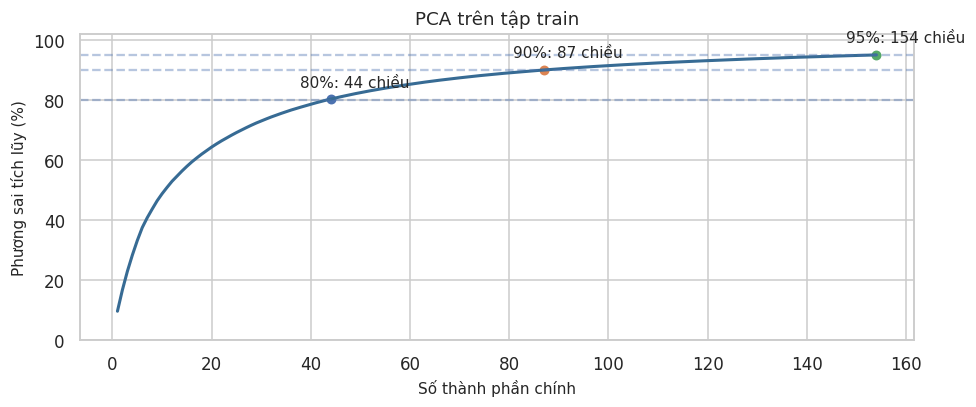

In [9]:
start = time.perf_counter()
x_train_norm = x_train_raw.astype(np.float32) / 255
x_train_flat = x_train_norm.reshape(-1, 784)
pca = PCA(n_components=0.95, random_state=SEED)
pca.fit(x_train_flat)
cumulative = np.cumsum(pca.explained_variance_ratio_) * 100
pca_dimension = int(pca.n_components_)
print(f'PCA: 784 → {pca_dimension} chiều | Thời gian fit: {time.perf_counter() - start:.2f} giây')
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(np.arange(1, len(cumulative) + 1), cumulative, color='#376b94', linewidth=2)
for threshold in [80, 90, 95]:
    dimension = int(np.searchsorted(cumulative, threshold) + 1)
    ax.axhline(threshold, linestyle='--', alpha=0.4)
    ax.scatter(dimension, cumulative[dimension - 1], s=30)
    ax.annotate(f'{threshold}%: {dimension} chiều', (dimension, cumulative[dimension - 1]), xytext=(-20, 8), textcoords='offset points')
ax.set(xlabel='Số thành phần chính', ylabel='Phương sai tích lũy (%)', title='PCA trên tập train', ylim=(0, 102))
show_figure('07_pca_phuong_sai')

### 8.1. Chiếu lên hai thành phần đầu

Biểu đồ chỉ hiển thị hai chiều đầu của PCA. Các điểm chồng lấn trong hình chưa đủ để kết luận
khả năng phân lớp của véc-tơ PCA đầy đủ.

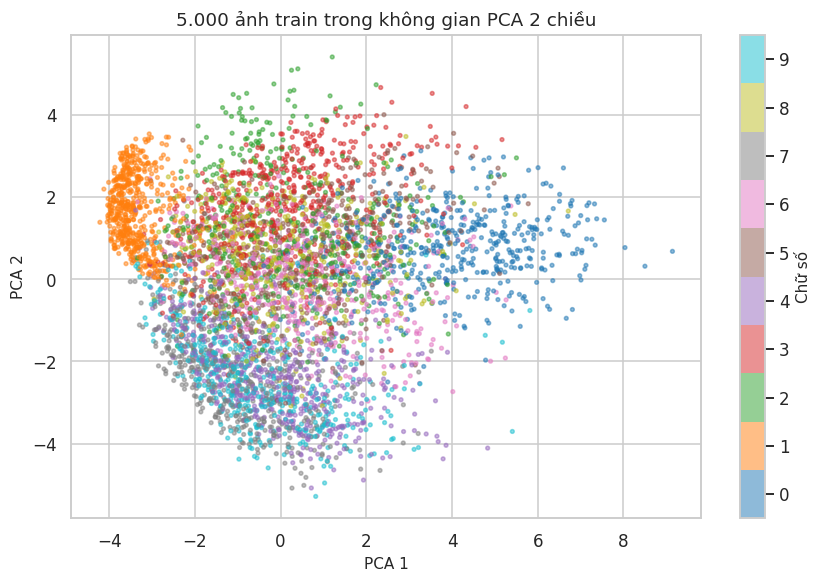

In [10]:
projection_indices = rng.choice(len(y_train_full), 5000, replace=False)
projection = pca.transform(x_train_flat[projection_indices])
fig, ax = plt.subplots(figsize=(8, 5.4))
scatter = ax.scatter(projection[:, 0], projection[:, 1], c=y_train_full[projection_indices], cmap='tab10', s=6, alpha=0.5, vmin=-0.5, vmax=9.5)
fig.colorbar(scatter, ax=ax, ticks=range(10), label='Chữ số')
ax.set(xlabel='PCA 1', ylabel='PCA 2', title='5.000 ảnh train trong không gian PCA 2 chiều')
show_figure('08_pca_hai_chieu')

Biểu đồ cho thấy hai thành phần PCA đầu tiên thể hiện được một phần khác biệt giữa các lớp chữ số:
- Số 1 (màu cam) tập trung khá rõ ở bên trái, ít chồng lấn hơn nhiều lớp khác.
- Số 0 (màu xanh dương) có xu hướng phân bố về bên phải, nhưng vẫn giao với các lớp khác.
- Vùng trung tâm có nhiều màu xen lẫn, cho thấy nhiều ảnh thuộc các lớp khác nhau có giá trị PCA 1 và PCA 2 gần nhau.
- Các điểm cùng màu cũng phân tán, phản ánh sự đa dạng về kiểu viết trong cùng một lớp.

Hai thành phần này chưa tách rõ cả 10 lớp. Tuy nhiên, biểu đồ chỉ hiển thị 2 chiều nên chưa đủ để kết luận về khả năng phân loại khi sử dụng đầy đủ các thành phần PCA.

## 9. Trực quan hóa t-SNE

Phép chiếu dùng 2.000 ảnh train, giảm trước về 50 thành phần PCA rồi chạy t-SNE.
Tập test không tham gia fit các bộ biến đổi trong phần này.

Tham số t-SNE: {'n_components': 2, 'perplexity': 30, 'init': 'pca', 'learning_rate': 'auto', 'random_state': 42, 'max_iter': 750}
Thời gian t-SNE: 4.01 giây


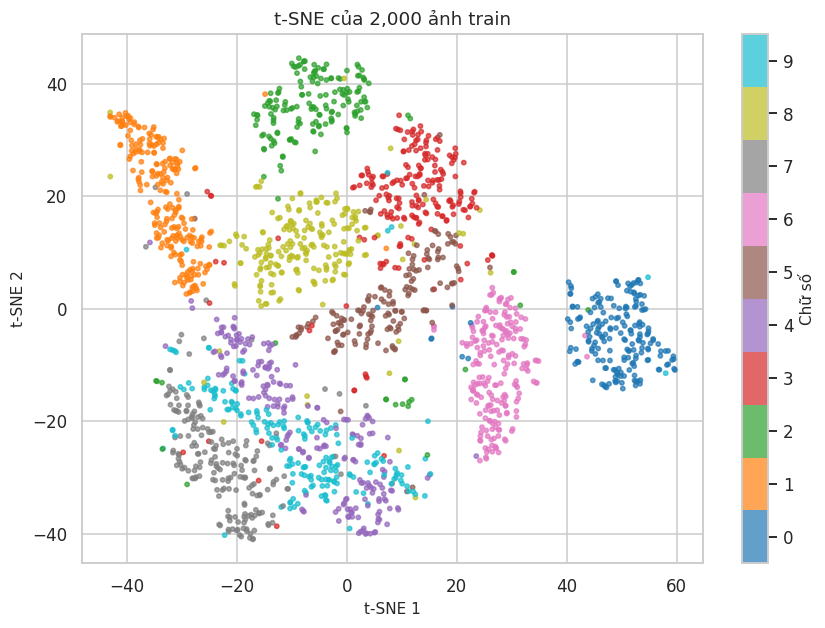

In [11]:
import inspect
TSNE_SAMPLES = 2000
TSNE_ITERATIONS = 750
tsne_indices = rng.choice(len(y_train_full), TSNE_SAMPLES, replace=False)
tsne_input = pca.transform(x_train_flat[tsne_indices])[:, :50]
tsne_params = {'n_components': 2, 'perplexity': 30, 'init': 'pca', 'learning_rate': 'auto', 'random_state': SEED}
iteration_key = 'max_iter' if 'max_iter' in inspect.signature(TSNE).parameters else 'n_iter'
tsne_params[iteration_key] = TSNE_ITERATIONS
print('Tham số t-SNE:', tsne_params)
start = time.perf_counter()
tsne_points = TSNE(**tsne_params).fit_transform(tsne_input)
print(f'Thời gian t-SNE: {time.perf_counter() - start:.2f} giây')
fig, ax = plt.subplots(figsize=(8, 5.8))
scatter = ax.scatter(tsne_points[:, 0], tsne_points[:, 1], c=y_train_full[tsne_indices], cmap='tab10', s=8, alpha=0.7, vmin=-0.5, vmax=9.5)
fig.colorbar(scatter, ax=ax, ticks=range(10), label='Chữ số')
ax.set(xlabel='t-SNE 1', ylabel='t-SNE 2', title=f't-SNE của {TSNE_SAMPLES:,} ảnh train')
show_figure('11_tsne')

t-SNE là phương pháp giảm chiều để trực quan hóa dữ liệu. Nó đưa mỗi ảnh có nhiều đặc trưng xuống 2 tọa độ, sao cho các ảnh có đặc điểm giống nhau thường nằm gần nhau.

- Các lớp 0, 1, 2 và 6 tạo thành những vùng khá rõ. Điều này cho thấy nhiều ảnh cùng lớp có đặc điểm tương đồng.
- Các lớp 3, 5 và 8 có vùng riêng nhưng vẫn xuất hiện một số điểm xen lẫn ở ranh giới.
- Các lớp 4, 7 và 9 chồng lấn nhiều hơn ở phía dưới biểu đồ, gợi ý một số kiểu viết có đặc điểm gần nhau.
- Một số chấm nằm giữa vùng của lớp khác; cần xem lại ảnh cụ thể mới biết đó là kiểu viết đặc biệt hay mẫu có vấn đề.

## 10. Mức tương đồng của ảnh trung bình

Ma trận Pearson dưới đây so sánh ảnh trung bình của các lớp; đây không phải ma trận nhầm lẫn của mô hình.

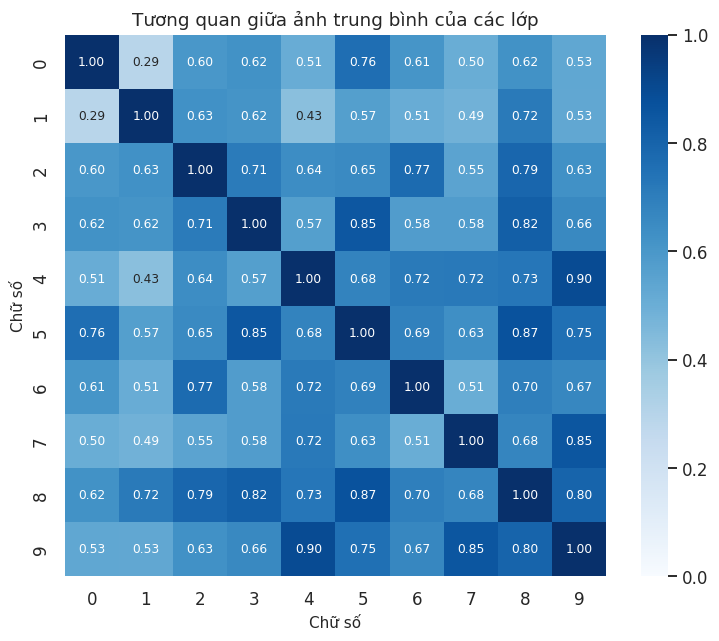

In [12]:
mean_images = np.stack([
    x_train_raw[y_train_full == digit].astype(np.float32).mean(axis=0) / 255
    for digit in range(10)
])
class_correlation = np.corrcoef(np.asarray(mean_images).reshape(10, -1))
fig, ax = plt.subplots(figsize=(7, 5.8))
sns.heatmap(class_correlation, annot=True, fmt='.2f', cmap='Blues', square=True, vmin=0, vmax=1,
            xticklabels=range(10), yticklabels=range(10), ax=ax, annot_kws={'size': 8})
ax.set(title='Tương quan giữa ảnh trung bình của các lớp', xlabel='Chữ số', ylabel='Chữ số')
show_figure('12_tuong_quan_anh_trung_binh')

## 11. Phân chia dữ liệu huấn luyện

Năm mô hình dùng cùng 50.000 ảnh train, 10.000 ảnh validation và 10.000 ảnh test.
Train và validation được chia có phân tầng từ 60.000 ảnh train gốc với seed 42.
PCA trong EDA mô tả 60.000 ảnh gốc. PCA của k-NN/SVM fit trên 50.000 ảnh train sau Deskew.


Giao chỉ số train và validation: 0


,Chữ số,Train 50k,Validation 10k,Test 10k
0,0,4936,987,980
1,1,5618,1124,1135
2,2,4965,993,1032
3,3,5109,1022,1010
4,4,4868,974,982
5,5,4518,903,892
6,6,4932,986,958
7,7,5221,1044,1028
8,8,4876,975,974
9,9,4957,992,1009


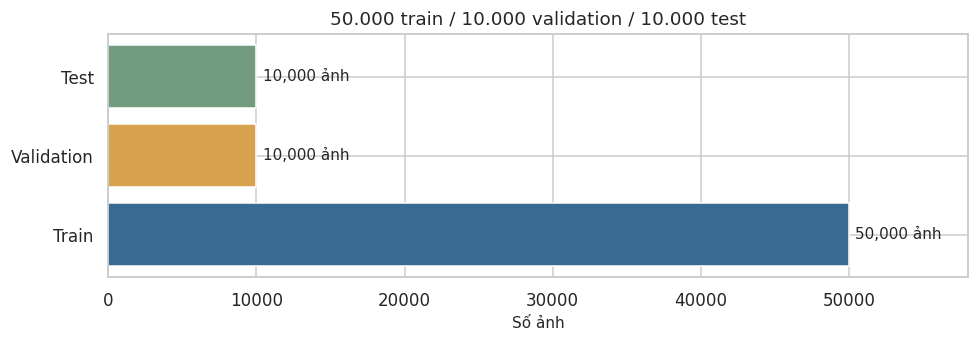

In [13]:
all_indices = np.arange(len(y_train_full))
train_indices, val_indices = train_test_split(
    all_indices, test_size=10000, stratify=y_train_full, random_state=SEED
)
assert not np.intersect1d(train_indices, val_indices).size
split_table = pd.DataFrame({
    'Chữ số': np.arange(10),
    'Train 50k': np.bincount(y_train_full[train_indices], minlength=10),
    'Validation 10k': np.bincount(y_train_full[val_indices], minlength=10),
    'Test 10k': test_counts,
})
display(split_table)
fig, ax = plt.subplots(figsize=(9, 3.2))
counts = [len(train_indices), len(val_indices), len(y_test)]
bars = ax.barh(['Train', 'Validation', 'Test'], counts,
              color=['#376b94', '#d6a24d', '#739c7e'])
ax.bar_label(bars, labels=[f'{v:,} ảnh' for v in counts], padding=4)
ax.set(xlabel='Số ảnh', title='50.000 train / 10.000 validation / 10.000 test', xlim=(0, 58000))
show_figure('13_chia_tap')
print('Giao chỉ số train và validation:', len(np.intersect1d(train_indices, val_indices)))
